# Banking Intent Classifier

Predicts which of 77 banking intents a customer message belongs to, using the BANKING77 dataset.

## Contents

1. Problem definition
2. Setup
3. Load the data
4. Explore the data
5. Preprocess and split the data
6. Baseline model
7. Train DistilBERT

## 1. Problem definition

### 1.1 The problem

Bank customers often contact support with short, free-text messages. Before a chatbot can help, it has to work out what the customer wants: its **intent**.

This project builds a classifier that takes one customer message and predicts one of 77 banking intents.

| Example customer message | Intent |
|---|---|
| "My card hasn't arrived yet" | `card_arrival` |
| "I think someone has been using my card" | `compromised_card` |
| "Why was I charged twice for the same purchase?" | `transaction_charged_twice` |

This is **single-label, multi-class text classification**.

### 1.2 Users and their needs

| User | Need |
|---|---|
| **Bank customers** | Reach the right help quickly, without repeating themselves or being sent to the wrong place |
| **Support teams** | Have routine requests handled automatically, and receive the cases that need a person |
| **Chatbot developers** | A model that is accurate, fast, and clear about when it is unsure |

### 1.3 Constraints and challenges

- **Many classes:** 77 intents is far harder than a typical sentiment task with two or three labels.
- **Very similar intents:** several intents share much of their vocabulary and differ only in meaning, as shown below.
- **Short messages:** a message gives little context, and the chatbot has no conversation history to draw on.
- **Limited data:** about 13,000 labelled messages across 77 intents, so each intent has relatively few examples.
- **Informal text:** real customers make typos and use casual wording.
- **Off-topic messages:** a real chatbot receives messages outside its 77 intents, but BANKING77 has no examples of these.
- **Response time:** a chatbot has to reply quickly, so model size and speed matter as well as accuracy.

| Similar intents | The difference |
|---|---|
| `lost_or_stolen_card` / `compromised_card` | The customer no longer has the card, or the card's details have been misused |
| `card_arrival` / `card_delivery_estimate` | An expected card is missing, or the customer wants to know how long delivery takes |
| `pending_transfer` / `transfer_not_received_by_recipient` | The transfer has not completed, or it appears sent but the recipient does not have it |

### 1.4 The cost of errors

Not all mistakes are equally serious, so overall accuracy alone is not enough.

| Severity | Example | Consequence |
|---|---|---|
| **High** | `lost_or_stolen_card` predicted as `card_not_working` | The card stays active while the customer gets troubleshooting steps, so there is a risk of financial loss |
| **Medium** | `transaction_charged_twice` predicted as `request_refund` | The customer gets the wrong process and has to contact support again |
| **Low** | `card_arrival` predicted as `card_delivery_estimate` | The answer is closely related, so it is a minor inconvenience |

For this reason, the system should say when it is unsure instead of always giving an answer, and the evaluation looks at results for each intent as well as overall scores.

### 1.5 Scope

**In scope**

- English messages about the 77 BANKING77 intents
- Predicting the most likely intents, with confidence scores
- Flagging messages that are off-topic or uncertain

**Out of scope**

- Carrying out actions, such as blocking a card or sending money
- Writing full chatbot replies
- Using conversation history
- Messages containing more than one request, since each example in the dataset has one label

This is a course project trained on a public dataset. It is not a production banking system.

### 1.6 Success criteria

These targets are set by this project, and later sections report whether each one was met.

| Requirement | Measure | Target |
|---|---|---|
| Correct classification | Macro F1 on the test set | At least 0.90 |
| Reported performance | Accuracy, precision, recall and F1 | All reported on the test set |
| Better than a simple approach | Macro F1 compared with the TF-IDF baseline | Higher than the baseline |
| Consistent across intents | Lowest-scoring intents | Identified and explained |
| Fast enough for a chatbot | Prediction time for one message on a CPU | Under 200 ms |
| Handles off-topic messages | Off-topic messages flagged, and banking messages wrongly flagged | At least 80% flagged, with under 10% wrongly flagged |
| Usable by a person | Working demo | A typed message returns the top intents with confidence scores |

## 2. Setup

Select a GPU first: **Runtime > Change runtime type > T4 GPU**. Then run these cells in order.

### 2.1 Install libraries

In [12]:
%pip install -q transformers==5.21.0 datasets==4.8.5 evaluate==0.4.6 accelerate==1.15.0 scikit-learn==1.6.1 gradio==6.30.0

### 2.2 Record library versions

These versions are pinned in `requirements.txt` so that the notebook can be reproduced.

In [13]:
import platform
from importlib.metadata import version

PACKAGES = [
    "transformers", "datasets", "evaluate", "accelerate", "torch",
    "scikit-learn", "pandas", "numpy", "matplotlib", "seaborn", "gradio",
]

print(f"# Python {platform.python_version()}")
for package in PACKAGES:
    print(f"{package}=={version(package)}")

# Python 3.13.16
transformers==5.21.0
datasets==4.8.5
evaluate==0.4.6
accelerate==1.15.0
torch==2.11.0+cu130
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
gradio==6.30.0


### 2.3 Check the GPU

In [14]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU found. Select Runtime > Change runtime type > T4 GPU, then run the notebook again."
    )

DEVICE = torch.device("cuda")
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
Memory: 15.6 GB


### 2.4 Connect Google Drive

Trained models are saved to Drive so that they survive Colab disconnects.

In [15]:
from pathlib import Path

from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/banking-intent-classifier")
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

for directory in (MODELS_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

test_file = PROJECT_DIR / "write_test.txt"
test_file.write_text("ok")
assert test_file.read_text() == "ok"
test_file.unlink()

print(f"Drive is ready: {PROJECT_DIR}")

Mounted at /content/drive
Drive is ready: /content/drive/MyDrive/banking-intent-classifier


### 2.5 Set the random seed

A fixed seed makes results repeatable.

In [16]:
import random

import numpy as np

SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print(f"Seed: {SEED}")

Seed: 42


## 3. Load the data

### 3.1 About the dataset

**BANKING77** (Casanueva et al., 2020, "Efficient Intent Detection with Dual Sentence Encoders") contains online banking queries, each labelled with one of 77 intents. It is released under the CC BY 4.0 license.

The files are loaded from the authors' repository, using a fixed commit so that the notebook always gets the same data.

In [17]:
import json
from urllib.request import urlopen

import pandas as pd

BANKING77_COMMIT = "57ec275d8078af65b7731c2a98be812d844a6d6b"
BANKING77_URL = (
    "https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/"
    f"{BANKING77_COMMIT}/banking_data"
)

# Two official intent names break the lowercase naming pattern.
LABEL_FIXES = {
    "Refund_not_showing_up": "refund_not_showing_up",
    "reverted_card_payment?": "reverted_card_payment",
}


def clean_labels(labels):
    return labels.replace(LABEL_FIXES)


def load_banking77():
    train = pd.read_csv(f"{BANKING77_URL}/train.csv")
    test = pd.read_csv(f"{BANKING77_URL}/test.csv")
    with urlopen(f"{BANKING77_URL}/categories.json") as response:
        categories = json.load(response)

    for split in (train, test):
        split["category"] = clean_labels(split["category"])

    intents = sorted(LABEL_FIXES.get(name, name) for name in categories)
    return train, test, intents


train_df, test_df, INTENTS = load_banking77()
print(f"Train messages: {len(train_df):,}")
print(f"Test messages: {len(test_df):,}")
print(f"Intents: {len(INTENTS)}")

Train messages: 10,003
Test messages: 3,080
Intents: 77


### 3.2 Map intents to numbers

Models work with numbers, so each intent gets a fixed ID. The IDs follow alphabetical order, so they are the same on every run.

In [18]:
LABEL2ID = {intent: index for index, intent in enumerate(INTENTS)}
ID2LABEL = {index: intent for intent, index in LABEL2ID.items()}

for split in (train_df, test_df):
    split["label"] = split["category"].map(LABEL2ID)

print(f"First intent: {ID2LABEL[0]}")
print(f"Last intent: {ID2LABEL[len(INTENTS) - 1]}")

First intent: activate_my_card
Last intent: wrong_exchange_rate_for_cash_withdrawal


### 3.3 Check the data

These checks stop the notebook if the data is not what the rest of the project expects.

In [19]:
EXPECTED_TRAIN_ROWS = 10_003
EXPECTED_TEST_ROWS = 3_080
EXPECTED_INTENTS = 77


def check_data(train, test, intents):
    assert len(train) == EXPECTED_TRAIN_ROWS, "Unexpected number of training rows"
    assert len(test) == EXPECTED_TEST_ROWS, "Unexpected number of test rows"
    assert len(intents) == len(set(intents)) == EXPECTED_INTENTS, "Unexpected intent list"

    for name, split in (("train", train), ("test", test)):
        assert split.notna().all().all(), f"Missing values in {name}"
        assert split["text"].str.strip().ne("").all(), f"Empty messages in {name}"
        assert set(split["category"]) == set(intents), f"Intents in {name} do not match the list"

    overlap = set(train["text"]) & set(test["text"])
    assert not overlap, f"{len(overlap)} messages appear in both train and test"


check_data(train_df, test_df, INTENTS)
print("All data checks passed")

All data checks passed


### 3.4 Preview the data

In [20]:
train_df.sample(5, random_state=SEED)

,text,category,label
6883,Is it possible for me to change my PIN number?,change_pin,21
5836,I'm not sure why my card didn't work,declined_card_payment,25
8601,I don't think my top up worked,top_up_failed,59
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged,15
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer,5


## 4. Explore the data

This section uses **only the training data**. The test set stays unseen until the final comparison, so that it gives a fair measure of performance.

In [21]:
import matplotlib.pyplot as plt
import numpy as np

BAR_COLOR = "#2a78d6"
SURFACE_COLOR = "#fcfcfb"
TEXT_COLOR = "#0b0b0b"
MUTED_COLOR = "#52514e"
GRID_COLOR = "#e5e4e0"

plt.rcParams.update({
    "figure.facecolor": SURFACE_COLOR,
    "axes.facecolor": SURFACE_COLOR,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": MUTED_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID_COLOR,
    "text.color": TEXT_COLOR,
    "xtick.color": MUTED_COLOR,
    "ytick.color": MUTED_COLOR,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / f"{name}.png")

### 4.1 Intent balance

In [22]:
intent_counts = train_df["category"].value_counts()

print(f"Fewest messages for an intent: {intent_counts.min()}")
print(f"Most messages for an intent: {intent_counts.max()}")
print(f"Median messages per intent: {intent_counts.median():.0f}")
print(f"Largest intent vs smallest: {intent_counts.max() / intent_counts.min():.1f} times")

Fewest messages for an intent: 35
Most messages for an intent: 187
Median messages per intent: 127
Largest intent vs smallest: 5.3 times


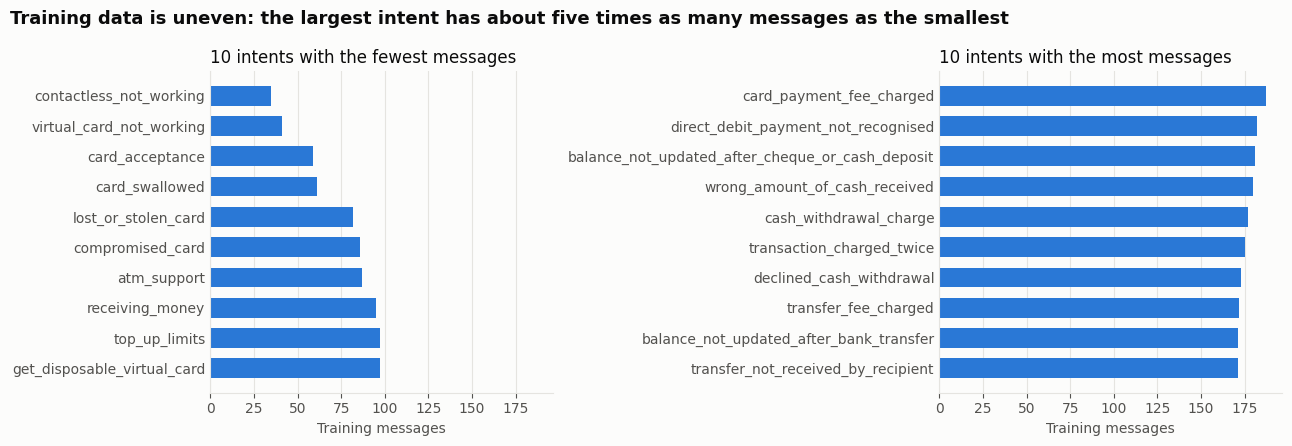

In [23]:
def plot_intent_balance(counts, top_n=10):
    figure, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
    panels = (
        (left, counts.tail(top_n), f"{top_n} intents with the fewest messages"),
        (right, counts.head(top_n).iloc[::-1], f"{top_n} intents with the most messages"),
    )
    for axis, values, title in panels:
        axis.barh(values.index, values.values, color=BAR_COLOR, height=0.65)
        axis.set_title(title)
        axis.set_xlabel("Training messages")
        axis.grid(axis="y", visible=False)
        axis.tick_params(axis="y", length=0)
    figure.suptitle(
        "Training data is uneven: the largest intent has about five times as many messages as the smallest",
        x=0.01, ha="left", fontsize=13, fontweight="bold",
    )
    figure.tight_layout()
    return figure


figure = plot_intent_balance(intent_counts)
save_figure(figure, "intent_balance")
plt.show()

**What this shows**

- The training data is uneven, from 35 messages (`contactless_not_working`) to 187 (`card_payment_fee_charged`).
- Three intents have fewer than 60 messages: `contactless_not_working`, `virtual_card_not_working` and `card_acceptance`. These may be harder to learn.
- Two of the high-risk intents are among the smallest: `lost_or_stolen_card` (82) and `compromised_card` (86). Scores for these need checking individually.
- The test set has exactly 40 messages per intent, so it does not share this imbalance.

**What this means for the project:** macro F1 is the main metric because it counts every intent equally. The validation split must be stratified, so that small intents keep their share.

### 4.2 Message length

In [24]:
word_counts = train_df["text"].str.split().str.len()

print(f"Median length: {word_counts.median():.0f} words")
print(f"95th percentile: {word_counts.quantile(0.95):.0f} words")
print(f"99th percentile: {word_counts.quantile(0.99):.0f} words")
print(f"Shortest: {word_counts.min()} words")
print(f"Longest: {word_counts.max()} words")

Median length: 10 words
95th percentile: 29 words
99th percentile: 43 words
Shortest: 2 words
Longest: 79 words


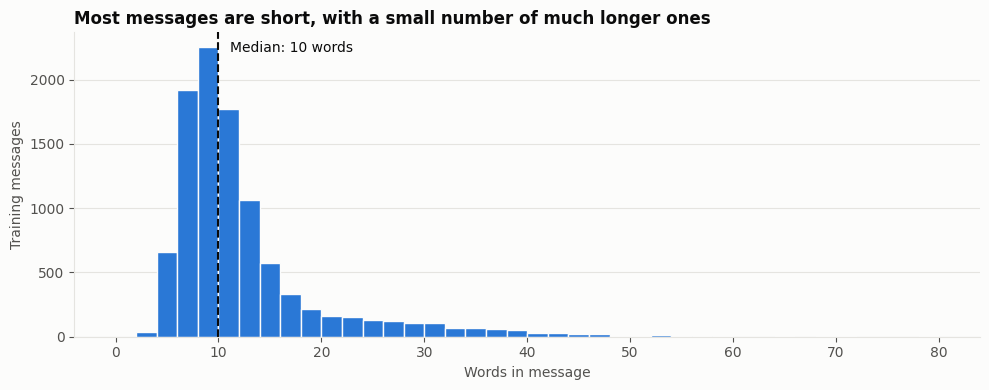

In [25]:
def plot_message_lengths(lengths):
    median = lengths.median()
    figure, axis = plt.subplots(figsize=(10, 4))
    axis.hist(lengths, bins=range(0, int(lengths.max()) + 3, 2), color=BAR_COLOR, edgecolor=SURFACE_COLOR)
    axis.axvline(median, color=TEXT_COLOR, linewidth=1.5, linestyle="--")
    axis.annotate(
        f"Median: {median:.0f} words",
        xy=(median, 1), xycoords=("data", "axes fraction"),
        xytext=(8, -14), textcoords="offset points", color=TEXT_COLOR,
    )
    axis.set_title("Most messages are short, with a small number of much longer ones", fontweight="bold")
    axis.set_xlabel("Words in message")
    axis.set_ylabel("Training messages")
    axis.grid(axis="x", visible=False)
    figure.tight_layout()
    return figure


figure = plot_message_lengths(word_counts)
save_figure(figure, "message_lengths")
plt.show()

**What this shows**

- Messages are short: half have 10 words or fewer, which confirms the limited context noted in section 1.3.
- A small group is much longer, with 42 messages over 50 words and a maximum of 79.

**What this means for the project:** the token limit is set in the next section using each model's own tokenizer. It needs to cover the long messages without wasting memory on padding.

### 4.3 Similar intents

Each intent is represented by the average TF-IDF vector of its messages. Cosine similarity between these vectors then shows which intents use the most similar wording.

In [26]:
from itertools import combinations

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def intent_similarity(data, intents):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
    vectors = vectorizer.fit_transform(data["text"])
    centroids = np.vstack([
        np.asarray(vectors[(data["category"] == intent).to_numpy()].mean(axis=0))
        for intent in intents
    ])
    similarity = cosine_similarity(centroids)
    pairs = [
        (intents[a], intents[b], similarity[a, b])
        for a, b in combinations(range(len(intents)), 2)
    ]
    table = pd.DataFrame(pairs, columns=["intent_a", "intent_b", "similarity"])
    table = table.sort_values("similarity", ascending=False, ignore_index=True)
    table["rank"] = table.index + 1
    return table


similarity_table = intent_similarity(train_df, INTENTS)
print(f"Median similarity across all {len(similarity_table):,} pairs: {similarity_table['similarity'].median():.2f}")
similarity_table.head(10).round(2)

Median similarity across all 2,926 pairs: 0.13


,intent_a,intent_b,similarity,rank
0,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,0.81,1
1,top_up_failed,top_up_reverted,0.77,2
2,pending_top_up,top_up_failed,0.75,3
3,verify_my_identity,why_verify_identity,0.74,4
4,pending_top_up,top_up_reverted,0.72,5
5,getting_virtual_card,virtual_card_not_working,0.71,6
6,card_payment_fee_charged,transfer_fee_charged,0.67,7
7,declined_card_payment,reverted_card_payment,0.67,8
8,cash_withdrawal_charge,transfer_fee_charged,0.67,9
9,card_payment_fee_charged,cash_withdrawal_charge,0.67,10


The pairs highlighted as similar in section 1.3 can be checked the same way:

In [27]:
SECTION_1_PAIRS = [
    ("lost_or_stolen_card", "compromised_card"),
    ("card_arrival", "card_delivery_estimate"),
    ("pending_transfer", "transfer_not_received_by_recipient"),
]


def find_pair(table, first, second):
    match = table["intent_a"].eq(min(first, second)) & table["intent_b"].eq(max(first, second))
    return table[match]


pd.concat([find_pair(similarity_table, *pair) for pair in SECTION_1_PAIRS]).round(2)

,intent_a,intent_b,similarity,rank
61,compromised_card,lost_or_stolen_card,0.48,62
73,card_arrival,card_delivery_estimate,0.46,74
48,pending_transfer,transfer_not_received_by_recipient,0.50,49


**What this shows**

- The most similar pairs share their topic and differ in one detail, such as `top_up_failed` and `top_up_reverted`.
- The three pairs from section 1.3 rank between 49th and 74th of 2,926 pairs. Their similarity is well above the median of 0.13, but they are not the closest pairs.

**What this means for the project:** word overlap alone may not separate these intents, which supports using transformers that take context into account. This is only a prediction, because similar wording does not prove that a model will confuse two intents. The error analysis tests it against real mistakes.

### 4.4 Data quality

In [28]:
def normalize_text(text):
    words_only = text.str.lower().str.replace(r"[^\w\s]", "", regex=True)
    return words_only.str.split().str.join(" ")


def data_quality_report(data):
    normalized = normalize_text(data["text"])
    labels_per_text = data.groupby(normalized)["category"].nunique()
    return pd.Series({
        "Exact duplicates": data["text"].duplicated().sum(),
        "Duplicates after ignoring case and punctuation": normalized.duplicated().sum(),
        "Same text with different intents": (labels_per_text > 1).sum(),
        "Messages of two words or fewer": (data["text"].str.split().str.len() <= 2).sum(),
        "Messages containing digits": data["text"].str.contains(r"\d").sum(),
        "Messages containing a currency symbol": data["text"].str.contains("[£€$]").sum(),
        "Messages entirely in lowercase": (data["text"] == data["text"].str.lower()).sum(),
    }, name="Messages")


data_quality_report(train_df).to_frame()

,Messages
Exact duplicates,0
Duplicates after ignoring case and punctuation,12
Same text with different intents,0
Messages of two words or fewer,6
Messages containing digits,212
Messages containing a currency symbol,114
Messages entirely in lowercase,440


**What this shows**

- The data is clean: no exact duplicates, and no message appears with two different intents.
- 12 messages repeat another message once case and punctuation are ignored. All have matching labels, so they cannot cause conflicting training signals.
- Very short messages such as "Lost password" exist, and they have very little context.
- Digits and currency symbols appear in some messages and can carry meaning, such as amounts.

**What this means for the project:** cleaning should stay light, because transformers benefit from natural text. The 12 near-duplicates need handling before the validation split, so that no message appears on both sides.

### 4.5 Summary

| Finding | Decision |
|---|---|
| Uneven training data | Use macro F1 as the main metric, and stratify the validation split |
| Small high-risk intents | Report `lost_or_stolen_card` and `compromised_card` individually |
| Short messages, with a few long ones | Set the token limit from the tokenizers' own counts |
| Similar wording across intents | Test the prediction against real errors in the error analysis |
| Clean text, with meaningful digits and symbols | Keep cleaning light |
| 12 near-duplicates | Remove them before the validation split |

## 5. Preprocess and split the data

This section applies the decisions from the exploration: light cleaning, removing near-duplicates, a stratified validation split, and tokenizing the text for each model.

### 5.1 Clean the text

Cleaning only tidies whitespace, because some messages contain line breaks, double spaces or non-breaking spaces. Case, punctuation, digits and currency symbols all stay, because transformers can use them.

In [29]:
def clean_text(text):
    return text.str.split().str.join(" ")


for split in (train_df, test_df):
    changed = (clean_text(split["text"]) != split["text"]).sum()
    split["text"] = clean_text(split["text"])
    print(f"Messages with whitespace tidied: {changed}")

Messages with whitespace tidied: 466
Messages with whitespace tidied: 103


### 5.2 Remove near-duplicates from the training data

Two kinds of near-duplicate are removed, ignoring case and punctuation:

- **Repeats within the training data**, so that no message can end up in both the training and validation splits.
- **Copies of test messages**, because a model that has already seen a test message would get an unfairly easy question.

Only training rows are removed. The test set stays exactly as published, so the results can be compared with other work on BANKING77.

In [30]:
def remove_near_duplicates(train, test):
    train_keys = normalize_text(train["text"])
    test_keys = set(normalize_text(test["text"]))

    repeated = train_keys.duplicated()
    in_test = train_keys.isin(test_keys)

    print(f"Repeats within the training data: {repeated.sum()}")
    print(f"Copies of test messages: {in_test.sum()}")
    return train[~(repeated | in_test)].reset_index(drop=True)


unique_train_df = remove_near_duplicates(train_df, test_df)
print(f"Training messages kept: {len(unique_train_df):,} of {len(train_df):,}")

Repeats within the training data: 12
Copies of test messages: 11
Training messages kept: 9,980 of 10,003


### 5.3 Create the validation split

The validation split is used to tune the models and choose between them, so that the test set is only used once at the end. The split is **stratified**, which keeps each intent's share the same on both sides.

In [31]:
from sklearn.model_selection import train_test_split

VALIDATION_SIZE = 0.1

train_split, val_split = train_test_split(
    unique_train_df,
    test_size=VALIDATION_SIZE,
    stratify=unique_train_df["label"],
    random_state=SEED,
)
train_split = train_split.reset_index(drop=True)
val_split = val_split.reset_index(drop=True)

split_sizes = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "messages": [len(train_split), len(val_split), len(test_df)],
    "fewest_per_intent": [
        split["label"].value_counts().min() for split in (train_split, val_split, test_df)
    ],
    "most_per_intent": [
        split["label"].value_counts().max() for split in (train_split, val_split, test_df)
    ],
})
split_sizes

,split,messages,fewest_per_intent,most_per_intent
0,train,8982,32,168
1,validation,998,3,19
2,test,3080,40,40


These checks stop the notebook if any message appears in more than one split, or if an intent is missing.

In [32]:
def check_splits(train, val, test, intents):
    keys = {
        "train": set(normalize_text(train["text"])),
        "validation": set(normalize_text(val["text"])),
        "test": set(normalize_text(test["text"])),
    }
    for first, second in combinations(keys, 2):
        shared = keys[first] & keys[second]
        assert not shared, f"{len(shared)} messages appear in both {first} and {second}"

    for name, split in (("train", train), ("validation", val), ("test", test)):
        assert set(split["category"]) == set(intents), f"Intents missing from {name}"


check_splits(train_split, val_split, test_df, INTENTS)
print("All split checks passed")

All split checks passed


### 5.4 Choose the token limit

Models read tokens rather than words, and each model splits text differently, so lengths are measured with each model's own tokenizer on the training split.

In [33]:
from transformers import AutoTokenizer

MODEL_CHECKPOINTS = {
    "DistilBERT": "distilbert-base-uncased",
    "RoBERTa": "roberta-base",
}

tokenizers = {
    name: AutoTokenizer.from_pretrained(checkpoint)
    for name, checkpoint in MODEL_CHECKPOINTS.items()
}


def token_lengths(tokenizer, texts):
    return pd.Series([len(ids) for ids in tokenizer(texts.tolist())["input_ids"]])


length_summary = pd.DataFrame({
    name: token_lengths(tokenizer, train_split["text"]).describe(percentiles=[0.5, 0.99])
    for name, tokenizer in tokenizers.items()
}).loc[["50%", "99%", "max"]].round(0).astype(int)
length_summary

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

,DistilBERT,RoBERTa
50%,13,13
99%,53,51
max,98,93


The longest training message is under 100 tokens for both models, so a limit of **128** cuts off nothing in the training split. Each batch is later padded only to its own longest message, so short messages do not waste memory despite the higher limit.

In [34]:
MAX_LENGTH = 128

for name, tokenizer in tokenizers.items():
    longest = token_lengths(tokenizer, train_split["text"]).max()
    assert longest <= MAX_LENGTH, f"{name} would truncate training messages"

print(f"Token limit: {MAX_LENGTH}")

Token limit: 128


### 5.5 Tokenize the data

Each model gets its own tokenized copy of all three splits. The TF-IDF baseline does not use these, as it works directly from the cleaned text.

In [35]:
from datasets import Dataset, DatasetDict


def build_dataset(train, val, test):
    return DatasetDict({
        name: Dataset.from_pandas(split[["text", "label"]], preserve_index=False)
        for name, split in (("train", train), ("validation", val), ("test", test))
    })


def tokenize_dataset(dataset, tokenizer):
    def tokenize_batch(batch):
        return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

    return dataset.map(tokenize_batch, batched=True, remove_columns=["text"])


dataset = build_dataset(train_split, val_split, test_df)
tokenized_datasets = {
    name: tokenize_dataset(dataset, tokenizer)
    for name, tokenizer in tokenizers.items()
}
dataset

Map:   0%|          | 0/8982 [00:00<?, ? examples/s]

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

Map:   0%|          | 0/8982 [00:00<?, ? examples/s]

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8982
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 998
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})

The same message looks different to each model:

In [36]:
EXAMPLE_MESSAGE = "Why was I charged £5 twice?"

for name, tokenizer in tokenizers.items():
    ids = tokenizer(EXAMPLE_MESSAGE)["input_ids"]
    print(f"{name}: {tokenizer.convert_ids_to_tokens(ids)}")

DistilBERT: ['[CLS]', 'why', 'was', 'i', 'charged', '£5', 'twice', '?', '[SEP]']
RoBERTa: ['<s>', 'Why', 'Ġwas', 'ĠI', 'Ġcharged', 'ĠÂ£', '5', 'Ġtwice', '?', '</s>']


**What this shows**

- DistilBERT lowercases everything, so "Why" and "why" are the same token to it.
- RoBERTa keeps capital letters, and marks the start of a new word with `Ġ`.

This is one reason for comparing the two models: they do not receive quite the same information.

## 6. Baseline model

A simple baseline shows how much the transformers actually add. If they cannot clearly beat it, their extra size and complexity are hard to justify.

The baseline has two parts:

- **TF-IDF** turns each message into a vector of word and phrase scores, with distinctive terms scoring higher.
- **Logistic regression** learns a weight for each term and each intent.

It treats a message as a bag of terms, so it has no real sense of word order or context beyond two-word phrases.

### 6.1 Scoring

The same scoring function is used for every model, so that the comparison is fair. Precision, recall and F1 are macro averages, which count every intent equally.

In [37]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


def compute_scores(true_labels, predicted_labels):
    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels, predicted_labels, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "precision": precision,
        "recall": recall,
        "macro_f1": f1,
    }

### 6.2 Tune the baseline

Each combination of settings is trained on the training split and scored on the validation split. The test set is not used.

| Setting | Options | What it controls |
|---|---|---|
| `ngram_range` | Single words, or words and two-word phrases | Whether phrases such as "top up" count as terms |
| `C` | 1, 10, 100 | How closely the model fits the training data, with higher values fitting more closely |
| `class_weight` | None, balanced | Whether errors on rare intents count for more during training |

In [38]:
from itertools import product

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

BASELINE_GRID = {
    "ngram_range": [(1, 1), (1, 2)],
    "C": [1, 10, 100],
    "class_weight": [None, "balanced"],
}


def build_baseline(ngram_range, C, class_weight):
    return make_pipeline(
        TfidfVectorizer(ngram_range=ngram_range, sublinear_tf=True),
        LogisticRegression(C=C, class_weight=class_weight, max_iter=2000, random_state=SEED),
    )


def tune_baseline(train, val, grid):
    results = []
    for values in product(*grid.values()):
        settings = dict(zip(grid, values))
        model = build_baseline(**settings)
        model.fit(train["text"], train["label"])
        scores = compute_scores(val["label"], model.predict(val["text"]))
        results.append({**settings, **scores})
    return pd.DataFrame(results).sort_values("macro_f1", ascending=False, ignore_index=True)


baseline_tuning = tune_baseline(train_split, val_split, BASELINE_GRID)
baseline_tuning.round(3)

,ngram_range,C,class_weight,accuracy,precision,recall,macro_f1
0,"(1, 1)",10,None,0.875,0.882,0.869,0.870
1,"(1, 1)",100,balanced,0.874,0.879,0.869,0.869
2,"(1, 2)",100,None,0.870,0.877,0.866,0.868
3,"(1, 2)",10,balanced,0.868,0.875,0.868,0.867
4,"(1, 1)",10,balanced,0.873,0.876,0.867,0.866
5,"(1, 1)",100,None,0.870,0.876,0.864,0.865
6,"(1, 2)",100,balanced,0.867,0.873,0.865,0.865
7,"(1, 2)",10,None,0.866,0.875,0.862,0.864
8,"(1, 2)",1,balanced,0.853,0.860,0.856,0.853
9,"(1, 1)",1,balanced,0.856,0.859,0.855,0.852


**What this shows**

- `C` matters most: every setting with `C` of 1 scores lowest.
- The top settings are very close, within about 0.01 macro F1. With 998 validation messages, differences this small may be noise, so the ranking near the top should not be over-interpreted.
- Two-word phrases and balanced class weights give no clear benefit here.

### 6.3 Train and save the best baseline

The best settings are chosen by validation macro F1. The model is trained on the training split only, which matches how the transformers will be trained.

In [39]:
import joblib

best_settings = baseline_tuning.loc[0, list(BASELINE_GRID)].to_dict()
print(f"Best settings: {best_settings}")

baseline_model = build_baseline(**best_settings)
baseline_model.fit(train_split["text"], train_split["label"])
joblib.dump(baseline_model, MODELS_DIR / "tfidf_baseline.joblib")

validation_scores = {
    "TF-IDF baseline": compute_scores(val_split["label"], baseline_model.predict(val_split["text"]))
}
pd.DataFrame(validation_scores).T.to_csv(RESULTS_DIR / "validation_scores.csv")
pd.DataFrame(validation_scores).T.round(3)

Best settings: {'ngram_range': (1, 1), 'C': 10, 'class_weight': None}


,accuracy,precision,recall,macro_f1
TF-IDF baseline,0.875,0.882,0.869,0.87


**What this shows**

- The baseline reaches a validation macro F1 of about 0.87. This is the score the transformers need to beat.
- It is already fairly strong for such a simple model, which suggests many intents have distinctive vocabulary.
- It falls short of the 0.90 target from section 1.6. That target applies to the final model, so this is not a failure of the baseline.

### 6.4 What the baseline learned

A benefit of this model is that its decisions can be inspected. These are the terms that most strongly point towards each of the similar high-risk intents.

In [40]:
def top_terms(model, intent, count=10):
    vectorizer, classifier = model.steps[0][1], model.steps[1][1]
    terms = vectorizer.get_feature_names_out()
    row = list(classifier.classes_).index(LABEL2ID[intent])
    strongest = np.argsort(classifier.coef_[row])[::-1][:count]
    return list(terms[strongest])


pd.DataFrame({
    intent: top_terms(baseline_model, intent)
    for intent in ("lost_or_stolen_card", "compromised_card")
})

,lost_or_stolen_card,compromised_card
0,stolen,someone
1,card,transactions
2,lost,fraud
3,missing,used
4,find,using
5,freeze,fraudulent
6,stole,replacement
7,my,think
8,took,stop
9,status,card


**What this shows**

- Many terms make sense, such as "stolen" and "lost" for `lost_or_stolen_card`, and "fraud" and "someone" for `compromised_card`.
- General words also carry weight, such as "my" and "card". The word "card" appears in both lists, so it does little to separate these intents.

**What this means for the project:** the model relies on individual words. A message that means "someone has my card" without using these words could be misclassified, which is where transformers should help. The test-set comparison and error analysis check whether they do.

## 7. Train DistilBERT

DistilBERT is a smaller, faster version of BERT. Unlike the baseline, it reads the whole message in order, so it can use context rather than individual words alone.

**Fine-tuning** starts from a model already trained on a large amount of general English text, and adapts it to banking intents. A new classification layer with 77 outputs is added on top.

Training code is shared with RoBERTa, so that both models get the same treatment and the comparison is fair.

### 7.1 Training settings

| Setting | Value | Why |
|---|---|---|
| Learning rates tried | 2e-5, 3e-5, 5e-5 | A common range for fine-tuning transformers, compared on the validation split |
| Maximum epochs | 10 | An upper limit, as early stopping usually ends training sooner |
| Early stopping | After 2 epochs without improvement | Stops training before the model overfits |
| Batch size | 32 | Fits comfortably in GPU memory for short messages |
| Weight decay | 0.01 | A light penalty on large weights, which helps reduce overfitting |
| Warmup | 1 epoch | Raises the learning rate gradually, which helps early training stay stable |

Each model is saved to Google Drive once tuning finishes. When a saved model exists, the notebook loads it instead of training again, so that **Run all** does not repeat long training runs. Set `RETRAIN = True` to train again.

In [41]:
import shutil
import time

from transformers import (
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
)

LEARNING_RATES = [2e-5, 3e-5, 5e-5]
MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64
WEIGHT_DECAY = 0.01
RETRAIN = False

CHECKPOINTS_DIR = Path("checkpoints")

### 7.2 Shared training code

DistilBERT's tokenized data includes a `token_type_ids` column that the model does not use. The `Trainer` removes columns a model does not accept, so this has no effect on training.

In [42]:
def trainer_metrics(prediction):
    logits, labels = prediction
    return compute_scores(labels, np.argmax(logits, axis=-1))


def build_training_args(output_dir, learning_rate, steps_per_epoch):
    return TrainingArguments(
        output_dir=str(output_dir),
        learning_rate=learning_rate,
        num_train_epochs=MAX_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        weight_decay=WEIGHT_DECAY,
        warmup_steps=steps_per_epoch,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        seed=SEED,
        report_to="none",
    )


def train_once(checkpoint, tokenizer, tokenized, learning_rate, output_dir):
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint,
        num_labels=len(INTENTS),
        id2label=ID2LABEL,
        label2id=LABEL2ID,
    )
    steps_per_epoch = len(tokenized["train"]) // BATCH_SIZE
    trainer = Trainer(
        model=model,
        args=build_training_args(output_dir, learning_rate, steps_per_epoch),
        train_dataset=tokenized["train"],
        eval_dataset=tokenized["validation"],
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=trainer_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
    )
    start = time.time()
    trainer.train()
    return trainer, time.time() - start


def epoch_history(trainer, learning_rate):
    logs = trainer.state.log_history
    train_loss = {row["epoch"]: row["loss"] for row in logs if "loss" in row}
    return pd.DataFrame([
        {
            "learning_rate": learning_rate,
            "epoch": row["epoch"],
            "train_loss": train_loss.get(row["epoch"]),
            "val_loss": row["eval_loss"],
            "val_macro_f1": row["eval_macro_f1"],
        }
        for row in logs if "eval_macro_f1" in row
    ])


def tune_transformer(name, checkpoint, tokenizer, tokenized, learning_rates):
    model_dir = MODELS_DIR / name.lower()
    tuning_path = RESULTS_DIR / f"{name.lower()}_tuning.csv"
    history_path = RESULTS_DIR / f"{name.lower()}_history.csv"

    if tuning_path.exists() and history_path.exists() and model_dir.exists() and not RETRAIN:
        print(f"Loading saved {name} results. Set RETRAIN = True to train again.")
        return pd.read_csv(tuning_path), pd.read_csv(history_path)

    tuning_rows = []
    histories = []
    best_f1 = -1.0
    for learning_rate in learning_rates:
        output_dir = CHECKPOINTS_DIR / f"{name.lower()}_{learning_rate}"
        trainer, seconds = train_once(checkpoint, tokenizer, tokenized, learning_rate, output_dir)
        history = epoch_history(trainer, learning_rate)
        histories.append(history)

        macro_f1 = history["val_macro_f1"].max()
        tuning_rows.append({
            "learning_rate": learning_rate,
            "best_val_macro_f1": macro_f1,
            "best_epoch": history.loc[history["val_macro_f1"].idxmax(), "epoch"],
            "epochs_run": history["epoch"].max(),
            "train_minutes": seconds / 60,
        })
        print(f"{name} at learning rate {learning_rate}: macro F1 {macro_f1:.3f} in {seconds / 60:.1f} minutes")

        if macro_f1 > best_f1:
            best_f1 = macro_f1
            trainer.save_model(model_dir)
            tokenizer.save_pretrained(model_dir)

        del trainer
        torch.cuda.empty_cache()
        shutil.rmtree(output_dir, ignore_errors=True)

    tuning = pd.DataFrame(tuning_rows).sort_values("best_val_macro_f1", ascending=False, ignore_index=True)
    history = pd.concat(histories, ignore_index=True)
    tuning.to_csv(tuning_path, index=False)
    history.to_csv(history_path, index=False)
    return tuning, history


def predict_labels(model_dir, tokenizer, data):
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir=str(CHECKPOINTS_DIR / "predict"),
            per_device_eval_batch_size=EVAL_BATCH_SIZE,
            report_to="none",
        ),
        data_collator=DataCollatorWithPadding(tokenizer),
    )
    return np.argmax(trainer.predict(data).predictions, axis=-1)


def plot_learning_curves(history, name, baseline_f1):
    colors = ["#2a78d6", "#eb6834", "#1baf7a"]
    figure, axis = plt.subplots(figsize=(10, 4.5))
    for color, (learning_rate, runs) in zip(colors, history.groupby("learning_rate")):
        axis.plot(
            runs["epoch"], runs["val_macro_f1"],
            color=color, linewidth=2, marker="o", markersize=7,
            label=f"Learning rate {learning_rate:g}",
        )
    axis.axhline(baseline_f1, color=MUTED_COLOR, linewidth=1.5, linestyle="--")
    axis.annotate(
        f"TF-IDF baseline: {baseline_f1:.3f}",
        xy=(1, baseline_f1), xycoords=("axes fraction", "data"),
        xytext=(-4, -14), textcoords="offset points", ha="right", color=MUTED_COLOR,
    )
    axis.set_title(f"{name} validation macro F1 by epoch", fontweight="bold")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Validation macro F1")
    axis.xaxis.get_major_locator().set_params(integer=True)
    axis.grid(axis="x", visible=False)
    axis.legend(frameon=False, loc="lower right")
    figure.tight_layout()
    return figure

### 7.3 Train and tune DistilBERT

This is the slowest cell so far, because it trains one model for each learning rate. Keep the Colab tab open while it runs.

In [43]:
distilbert_tuning, distilbert_history = tune_transformer(
    "DistilBERT",
    MODEL_CHECKPOINTS["DistilBERT"],
    tokenizers["DistilBERT"],
    tokenized_datasets["DistilBERT"],
    LEARNING_RATES,
)
distilbert_tuning.round({"best_val_macro_f1": 3, "train_minutes": 1})

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,Macro F1
1,4.098731,3.275498,0.437876,0.434947,0.419584,0.360702
2,2.493433,1.617620,0.747495,0.726129,0.707211,0.683696
3,1.293313,0.877813,0.844689,0.842211,0.822609,0.819406
4,0.721884,0.587093,0.884770,0.887795,0.866131,0.867060
5,0.452704,0.462885,0.893788,0.899922,0.884056,0.884407
6,0.307739,0.413475,0.899800,0.907475,0.893202,0.894818
7,0.219729,0.374671,0.912826,0.917917,0.905275,0.907179
8,0.170105,0.359347,0.915832,0.920087,0.910486,0.911189
9,0.140486,0.356826,0.912826,0.915399,0.907580,0.908170
10,0.120042,0.355790,0.914830,0.918680,0.909949,0.910944


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (38 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT at learning rate 5e-05: macro F1 0.921 in 5.4 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,learning_rate,best_val_macro_f1,best_epoch,epochs_run,train_minutes
0,0.00005,0.921,9.0,10.0,5.4
1,0.00003,0.914,9.0,10.0,4.0
2,0.00002,0.911,8.0,10.0,4.8


### 7.4 Learning curves

These curves show how validation macro F1 changes during training, compared with the baseline.

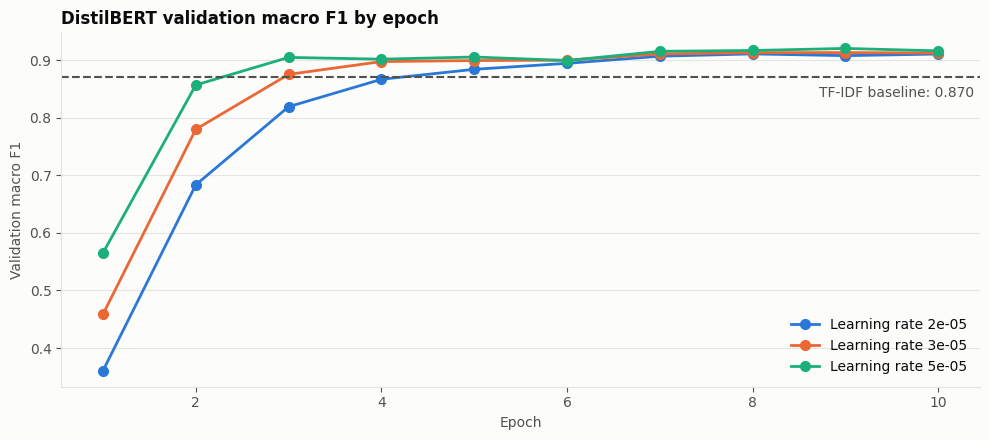

In [44]:
figure = plot_learning_curves(
    distilbert_history, "DistilBERT", validation_scores["TF-IDF baseline"]["macro_f1"]
)
save_figure(figure, "distilbert_learning_curves")
plt.show()

### 7.5 Score the saved model

The saved model is loaded back from Google Drive and scored, which confirms that the saved copy works. The test set is still not used.

In [45]:
def add_validation_scores(name):
    predictions = predict_labels(
        MODELS_DIR / name.lower(), tokenizers[name], tokenized_datasets[name]["validation"]
    )
    validation_scores[name] = compute_scores(val_split["label"], predictions)
    table = pd.DataFrame(validation_scores).T
    table.to_csv(RESULTS_DIR / "validation_scores.csv")
    return table.round(3)


add_validation_scores("DistilBERT")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,accuracy,precision,recall,macro_f1
TF-IDF baseline,0.875,0.882,0.869,0.870
DistilBERT,0.923,0.927,0.919,0.921
